In [2]:
import bls2017
import myplotutils as mpu
import matplotlib.pyplot as plt
import cv2
import tensor_list_to_tfrecord
import tensorflow as tf

2023-12-21 14:46:22.939267: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-12-21 14:46:24.879297: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [3]:
class Args:
    def __init__(self, model_path, input_file, output_file, verbose):
        self.model_path = model_path
        self.input_file = input_file
        self.output_file = output_file
        self.verbose = verbose

In [4]:
def parse_args_compress(models_path, data_path, model, image):
    model_path = models_path + model
    input_file = data_path + image
    output_file = input_file + '_' + model + ".tfci"
    verbose = True  
    args = Args(model_path, input_file, output_file, verbose)
    return args

In [5]:
def parse_args_decompress(models_path, data_path, model, image):
    model_path = models_path + model
    input_file = data_path + image + '_' + model + ".tfci"
    output_file = input_file + ".png"
    verbose = True  
    args = Args(model_path, input_file, output_file, verbose)
    return args

In [6]:
def evaluate_performance(models_path, data_path, image, models, verbose):
    hist_mse = []
    hist_psnr = []
    hist_msssim = []
    hist_msssim_db = []
    hist_bpp = []

    if verbose:
        print("\n --- PERFORMANCE EVALUTATION --- ")
        
    for model in models:
        mse, psnr, msssim, msssim_db, bpp = bls2017.compress(parse_args_compress(models_path, data_path, model, image))
        hist_mse.append(mse)
        hist_psnr.append(psnr)
        hist_msssim.append(msssim)
        hist_msssim_db.append(msssim_db)
        hist_bpp.append(bpp)

        if verbose:
            print("\nModel", model)
            print(f" --- Mean squared error: {mse:0.4f}")
            print(f" --- PSNR (dB): {psnr:0.2f}")
            print(f" --- Multiscale SSIM: {msssim:0.4f}")
            print(f" --- Multiscale SSIM (dB): {msssim_db:0.2f}")
            print(f" --- Bits per pixel: {bpp:0.4f}")
        
        bls2017.decompress(parse_args_decompress(models_path, data_path, model, image))
    
    return hist_bpp, hist_mse


In [22]:
def show_results(data_path, image_name, models):
    
    # select images paths
    images = []
    titles = []
    for model in models:
        image_path = data_path + image_name + '_' + model + ".tfci" + ".png"
        image = cv2.imread(image_path)
        image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
        images.append(image)
        titles.append(model)

    mpu.show_images(images, titles, size=25, columns=3)

In [8]:
def plot_rate_distortion_curve(image_name, hist_bpp, hist_mse, labels):
    
    plt.grid(True)
    plt.title(image_name)
    plt.xlabel("Bit rate [bit/pixel]")
    plt.ylabel("MSE")
    plt.plot(hist_bpp, hist_mse, linestyle='-', marker='o', markersize=3.5, color='r')

    # Add LaTeX text labels for each point
    for label, xi, yi in zip(labels, hist_bpp, hist_mse):
        plt.text(xi, yi, label, color='black', fontsize=12, ha='left', va='bottom')

# Features analysis

In [11]:
# NEED TO MANUALLY SET LENGTH GLOBAL PARAMETER TO MAKE IT WORK
# SET LENGTH = 7 in the read function
[x, x1, x2, y, x2_hat, x1_hat, x_hat] = tensor_list_to_tfrecord.read_tensor_list('intermediate_features.data')

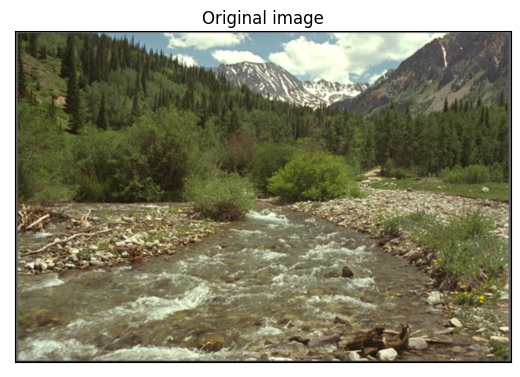

Image shape: (512, 768, 3)
Image data type: <dtype: 'uint8'>


In [12]:
x = tf.cast(x, tf.uint8)
mpu.show_image(x, 'Original image')

### Features after 1st convolution + downsampling (4) + GDN

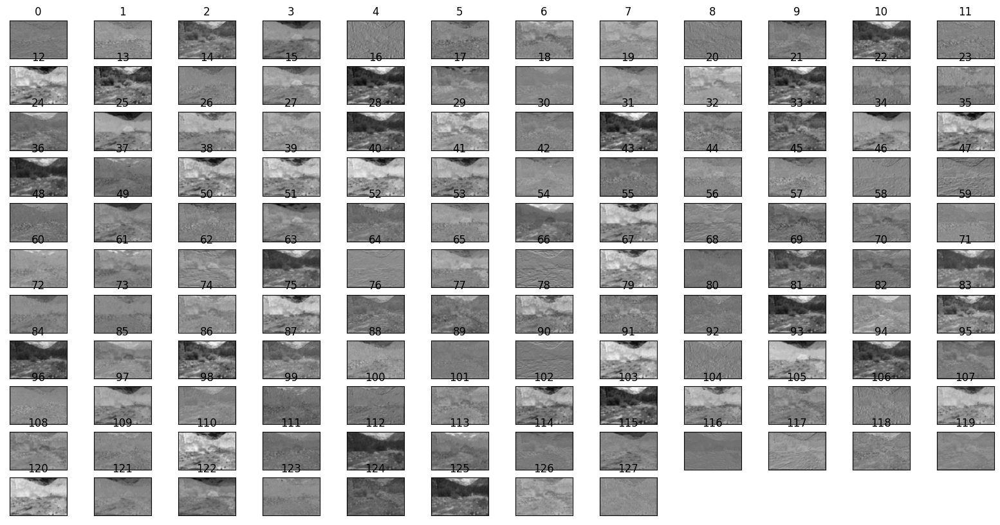

In [13]:
mpu.show_figures([x1[0, :,:,i] for i in range(128)], columns = 12)

### Features after 2nd convolution + downsampling (2) + GDN

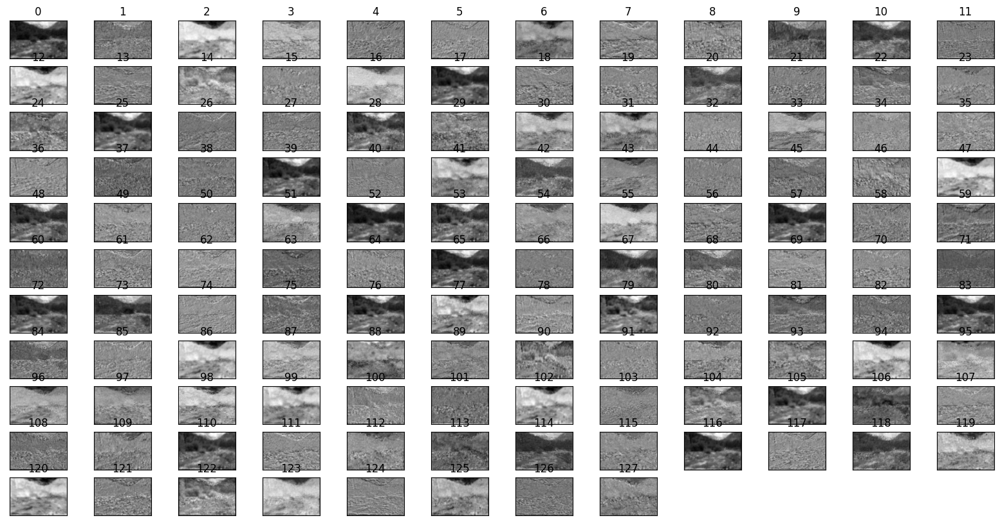

In [14]:
mpu.show_figures([x2[0, :,:,i] for i in range(128)], columns = 12)

### Features after 3rd convolution + downsampling (2) + GDN

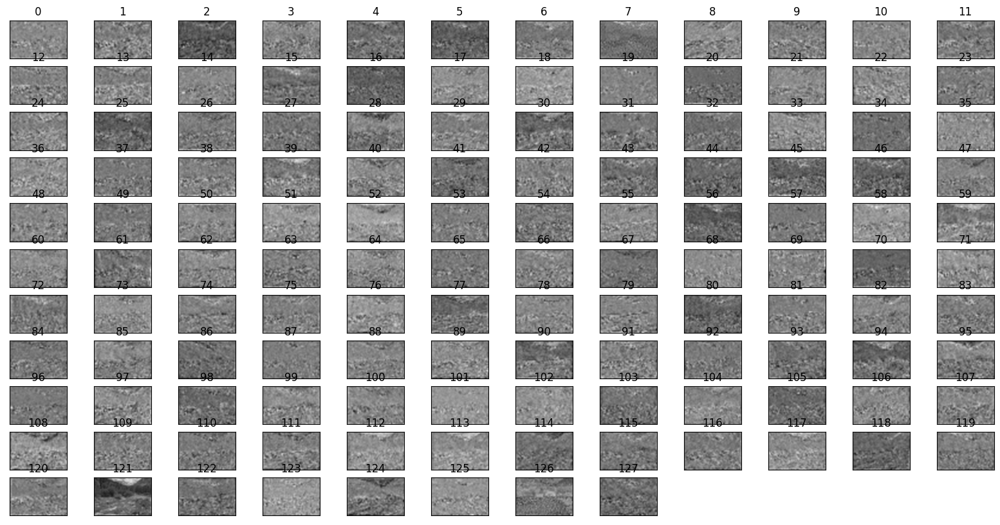

In [15]:
mpu.show_figures([y[0, :,:,i] for i in range(128)], size=20, columns = 12)

### Synthesis transform

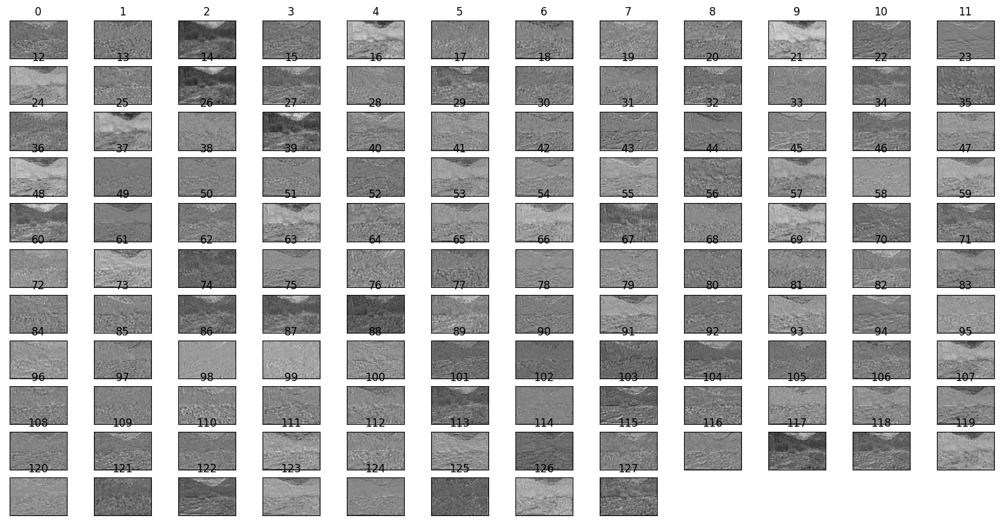

In [16]:
mpu.show_figures([x2_hat[0, :,:,i] for i in range(128)], columns = 12)

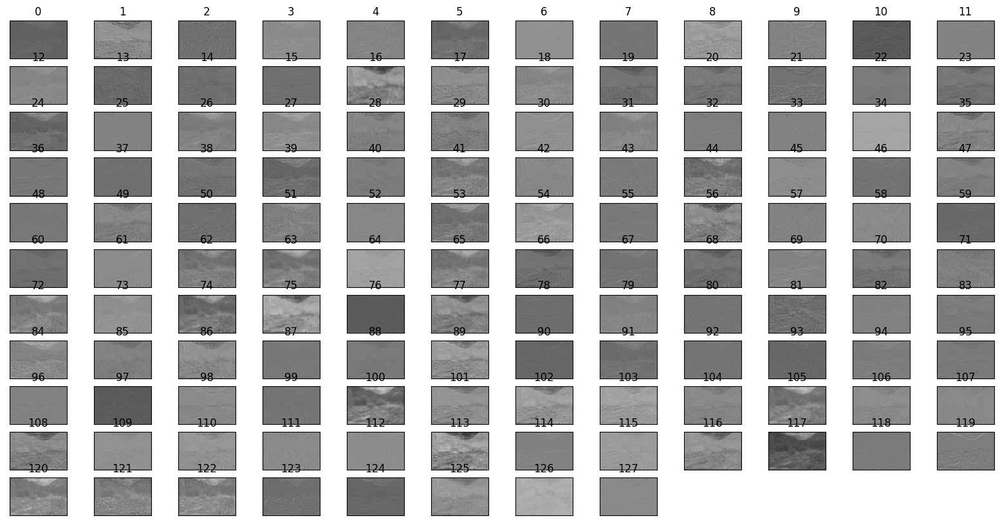

In [17]:
mpu.show_figures([x1_hat[0, :,:,i] for i in range(128)], columns = 12)

### Original vs reconstructed

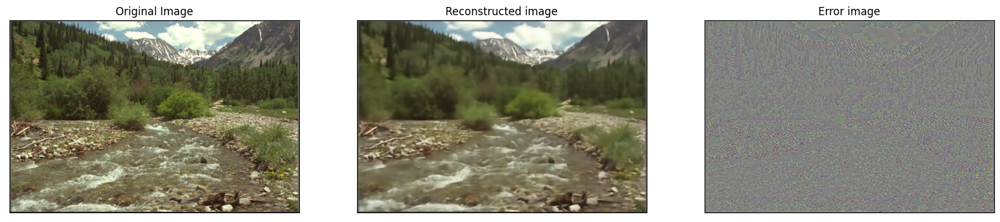

In [18]:
mpu.show_images([x, x_hat, x-x_hat+128], titles=["Original Image", "Reconstructed image", "Error image"], columns=3)

# Performance analysis

In [19]:
# Setting paths and models

models_path = 'models/'
data_path = 'test_images/'

models = [
          'bls2017_lambda_000_001', # lambda = 0.001 
          'bls2017_lambda_000_010', # lambda = 0.01
          'bls2017_lambda_000_100', # lambda = 0.1
          'bls2017_lambda_001_000', # lambda = 1
          'bls2017_lambda_010_000', # lambda = 10
          'bls2017_lambda_100_000'  # lambda = 100
        ]

labels = ['L: 0,001','L: 0,01','L: 0,1','L: 1','L: 10','L: 100']


image = 'kodim2/kodim02.png'

In [20]:
hist_bpp, hist_mse = evaluate_performance(models_path, data_path, image, models, verbose=True)


 --- PERFORMANCE EVALUTATION --- 

Model bls2017_lambda_000_001
 --- Mean squared error: 141.6108
 --- PSNR (dB): 26.62
 --- Multiscale SSIM: 0.8376
 --- Multiscale SSIM (dB): 7.89
 --- Bits per pixel: 0.0763

Model bls2017_lambda_000_010
 --- Mean squared error: 54.8374
 --- PSNR (dB): 30.74
 --- Multiscale SSIM: 0.9335
 --- Multiscale SSIM (dB): 11.77
 --- Bits per pixel: 0.3705

Model bls2017_lambda_000_100
 --- Mean squared error: 22.1958
 --- PSNR (dB): 34.67
 --- Multiscale SSIM: 0.9779
 --- Multiscale SSIM (dB): 16.55
 --- Bits per pixel: 1.2266

Model bls2017_lambda_001_000
 --- Mean squared error: 26.6825
 --- PSNR (dB): 33.87
 --- Multiscale SSIM: 0.9801
 --- Multiscale SSIM (dB): 17.01
 --- Bits per pixel: 1.9695

Model bls2017_lambda_010_000
 --- Mean squared error: 21.1471
 --- PSNR (dB): 34.88
 --- Multiscale SSIM: 0.9846
 --- Multiscale SSIM (dB): 18.12
 --- Bits per pixel: 2.1215

Model bls2017_lambda_100_000
 --- Mean squared error: 23.1689
 --- PSNR (dB): 34.48
 --- 

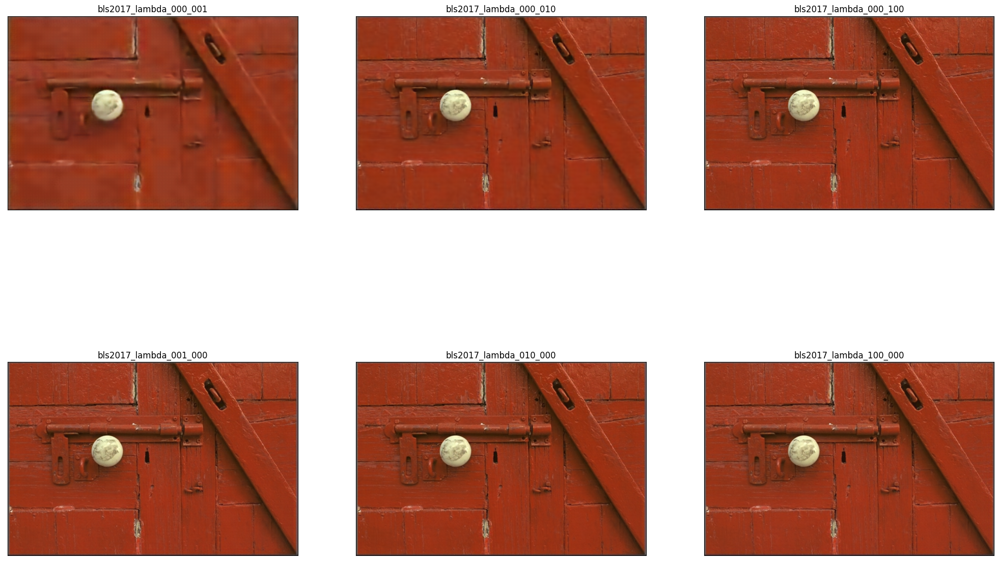

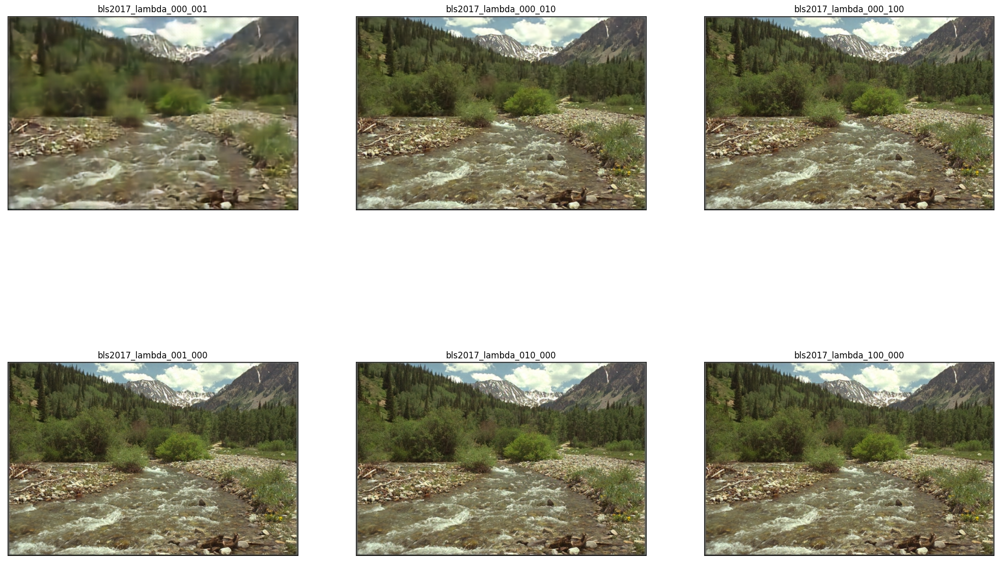

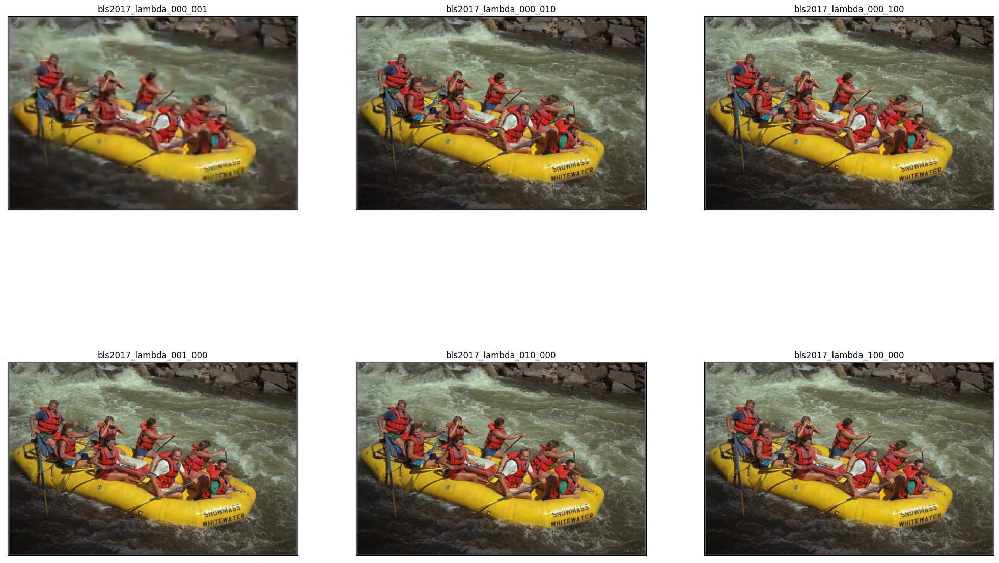

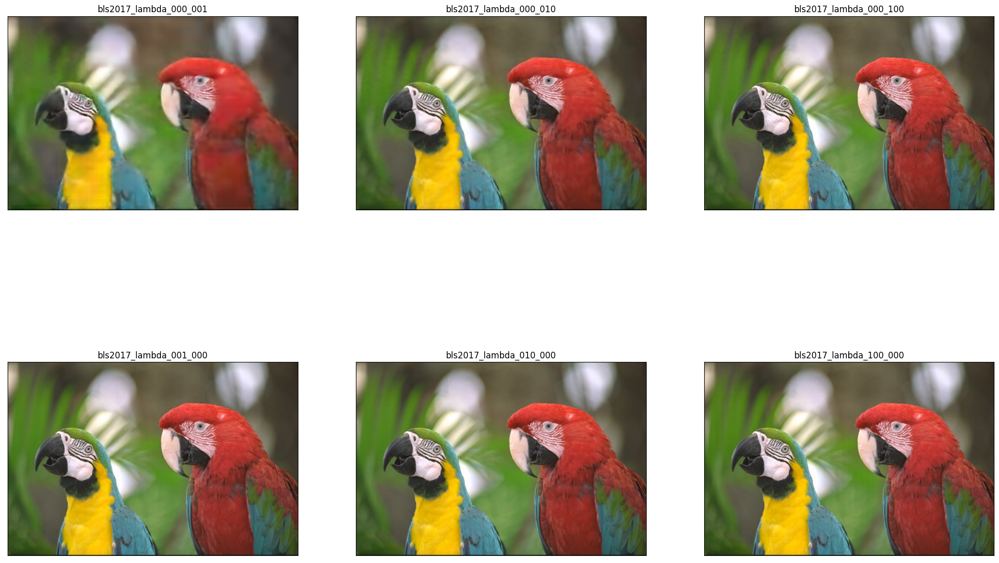

In [23]:
images = ['kodim2/kodim02.png',
          'kodim13/kodim13.png',
          'kodim14/kodim14.png',
          'kodim23/kodim23.png']

for image in images:
    show_results(data_path, image, models)

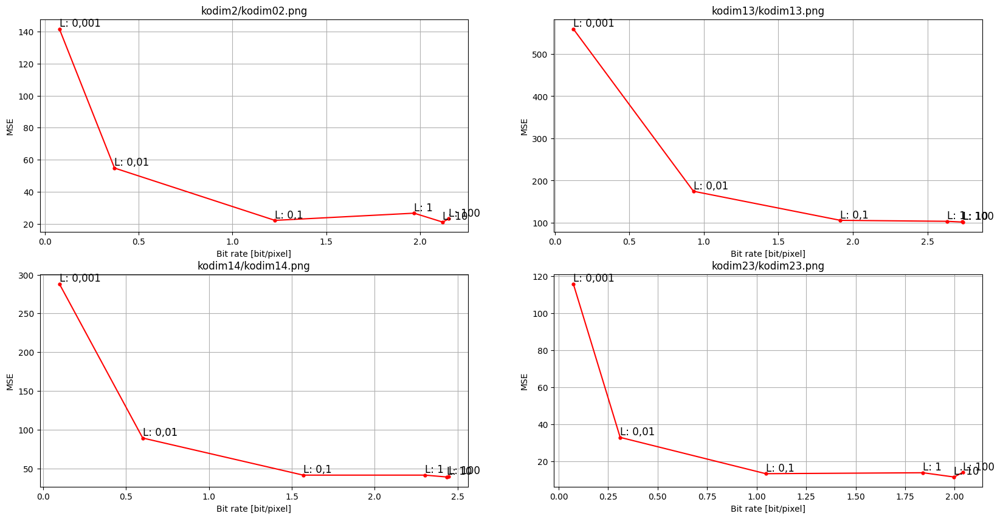

In [24]:
images = ['kodim2/kodim02.png',
          'kodim13/kodim13.png',
          'kodim14/kodim14.png',    
          'kodim23/kodim23.png']

plt.figure(figsize=(20,10))

r = 2; c = 2
for i in range(1,r*c+1):
    plt.subplot(r, c, i)
    hist_bpp, hist_mse = evaluate_performance(models_path, data_path, images[i-1], models, verbose=False)
    plot_rate_distortion_curve(images[i-1], hist_bpp, hist_mse, labels)